<a href="https://colab.research.google.com/github/haydencase0/MachineLearning/blob/main/Team4Module2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import ggplot, aes, geom_col, theme_minimal, labs
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

from pathlib import Path

# Works when launched from the project root or the notebooks directory.
NOTEBOOK_DIR = Path.cwd() if Path("bank.ipynb").exists() else Path.cwd() / "notebooks"
DATA_DIR = NOTEBOOK_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
DATA_URL = "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/"

def course_csv(filename):
    local_path = DATA_DIR / filename
    if not local_path.exists():
        pd.read_csv(DATA_URL + filename).to_csv(local_path, index=False)
    return local_path

In [2]:
data = pl.read_csv(course_csv("bank.csv"), infer_schema_length=10000)
data

age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
i64,str,str,str,str,str,str,str,str,str,i64,i64,i64,str,f64,f64,f64,f64,f64,str
56,"""housemaid""","""married""","""basic.4y""","""no""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
57,"""services""","""married""","""high.school""","""unknown""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
37,"""services""","""married""","""high.school""","""no""","""yes""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
40,"""admin.""","""married""","""basic.6y""","""no""","""no""","""no""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
56,"""services""","""married""","""high.school""","""no""","""no""","""yes""","""telephone""","""may""","""mon""",1,999,0,"""nonexistent""",1.1,93.994,-36.4,4.857,5191.0,"""no"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
73,"""retired""","""married""","""professional.course""","""no""","""yes""","""no""","""cellular""","""nov""","""fri""",1,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""yes"""
46,"""blue-collar""","""married""","""professional.course""","""no""","""no""","""no""","""cellular""","""nov""","""fri""",1,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""no"""
56,"""retired""","""married""","""university.degree""","""no""","""yes""","""no""","""cellular""","""nov""","""fri""",2,999,0,"""nonexistent""",-1.1,94.767,-50.8,1.028,4963.6,"""no"""


## Comparing the correct rows

The submission predicts **bank_holdout_test.csv**, which contains different customers from **bank.csv**. For example, record 3 in bank.csv is a 37-year-old married services worker; record 3 in the holdout is a 45-year-old divorced administrator. Their row numbers do not identify the same customer.

The holdout has no known `y` column. To measure accuracy, reserve labeled rows from bank.csv and compare each prediction with its own actual outcome. The validation table below keeps the original bank.csv record number (starting at 1, excluding the header). The submission remains one `y` column with **yes = 1, no = 0**, in holdout order.

## Model selection and accuracy

Keep numerical features numerical, and learn categorical encoding within each training fold. Compare a regularized decision tree and a random forest using three-fold cross-validation on the training portion only. Keep all 19 source features instead of automatically discarding everything outside the top eight.

We optimize overall accuracy and report positive-class precision and recall as well. The earlier balanced class weights favored predicting "yes"; fewer false positives can mean missing more subscribers. Always predicting "no" is a useful baseline because only about 11.35% of bank.csv is "yes".

Evaluate the selected model once on the reserved 30%, then refit a separate copy on all labeled rows for the final submission. The analysis charts use observed outcomes from bank.csv.

For the Value of Calls grading, the section below also tests probability thresholds using $44.64 per successful call minus $5.50 per call. The original accuracy-selected model is retained as the baseline; threshold selection optimizes call value. Both notebooks use the same stratified 30% validation split (random_state=42). The best threshold score is a tuning result, not an independent test estimate.

identifying those customers most likely to subscribe to a term deposit

find any actionable patterns in our results.
Should we only call single people on Saturdays?
Does it make sense to call students at all?

does contacting people too frequently for these marketing campaigns have an adverse affect on the outcome?

there are a bunch of social and economic indicators in the data.
We should be careful about how we consider these. We may want to see separate models for times when, for example, the consumer confidence index is high compared to when it is low.

Selected settings: {'model': RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=42), 'model__max_depth': None, 'model__min_samples_leaf': 3}
Cross-validation accuracy: 0.9000


Always-no baseline accuracy: 0.8865
Validation accuracy: 0.9018
False positives (actual no, predicted yes): 194
False negatives (actual yes, predicted no): 898


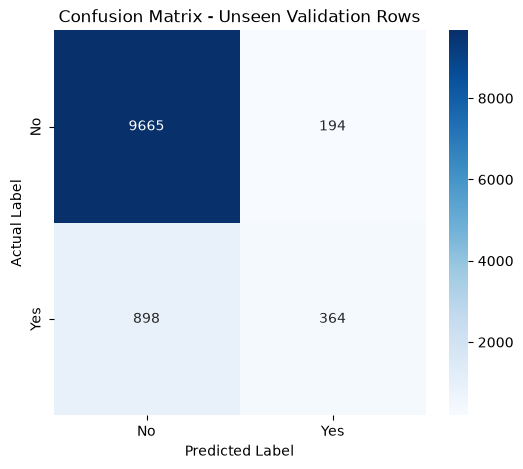

In [3]:
features = ['age', 'job', 'marital', 'education', 'default', 'housing',
            'loan', 'contact', 'month', 'day_of_week', 'campaign',
            'pdays', 'previous', 'emp.var.rate', 'cons.price.idx',
            'cons.conf.idx', 'euribor3m', 'nr.employed', 'poutcome']

# Preserve numerical values; encode only string-valued features.
X = data.select(features).to_pandas()
y = data.get_column("y").to_numpy()
categorical_features = [f for f in features if data.schema[f] == pl.String]
numeric_features = [f for f in features if f not in categorical_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    [
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
        ("numeric", "passthrough", numeric_features),
    ],
    verbose_feature_names_out=False,
)
pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42)),
])

# Tune on the training split only. Default class weights preserve prevalence.
param_grid = [
    {
        "model": [DecisionTreeClassifier(random_state=42)],
        "model__max_depth": [4, 6, 8, 12],
        "model__min_samples_leaf": [10, 30],
    },
    {
        "model": [RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1)],
        "model__max_depth": [12, None],
        "model__min_samples_leaf": [3, 10],
    },
]
search = GridSearchCV(
    pipeline, param_grid, scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=2,
)
search.fit(X_train, y_train)
clf = search.best_estimator_
print("Selected settings:", search.best_params_)
print(f"Cross-validation accuracy: {search.best_score_:.4f}")

# These rows were excluded from encoding, model fitting, and tuning.
validation_predictions = clf.predict(X_test)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Always-no baseline accuracy: {baseline.score(X_test, y_test):.4f}")
print(f"Validation accuracy: {accuracy_score(y_test, validation_predictions):.4f}")

cm = confusion_matrix(y_test, validation_predictions, labels=["no", "yes"])
tn, fp, fn, tp = cm.ravel()
print(f"False positives (actual no, predicted yes): {fp}")
print(f"False negatives (actual yes, predicted no): {fn}")
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Unseen Validation Rows")
plt.show()

# Use observed outcomes for the business analysis charts.
clean = data

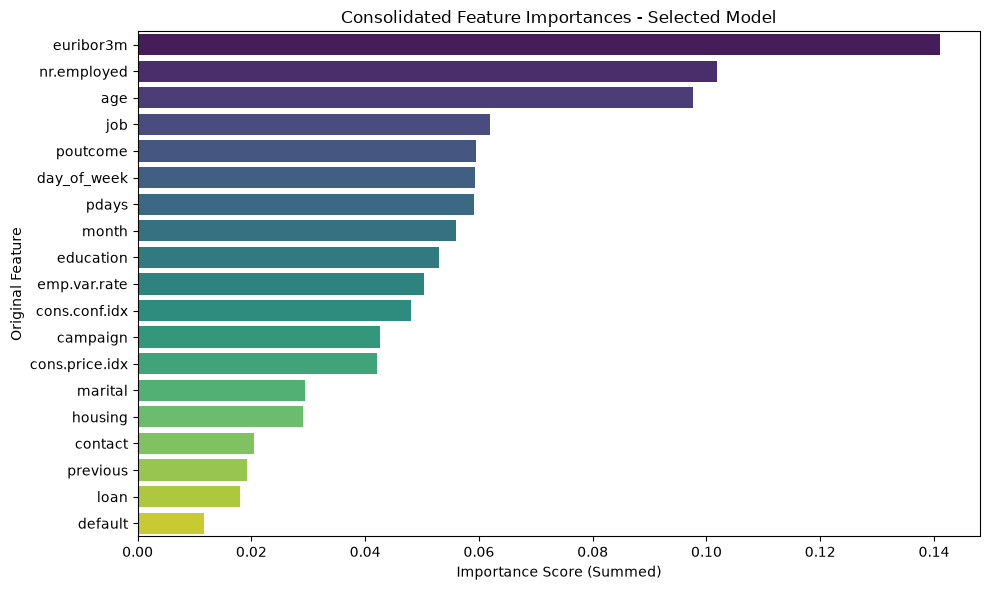

In [4]:
# Group the selected model's encoded-feature importances by source feature.
importances = clf.named_steps["model"].feature_importances_
feature_names = clf.named_steps["preprocess"].get_feature_names_out()

mapped_importances = []
for col_name, imp in zip(feature_names, importances):
    parent = next(
        (f for f in sorted(features, key=len, reverse=True)
         if col_name == f or col_name.startswith(f + "_")),
        col_name,
    )
    mapped_importances.append({"Original_Feature": parent, "Importance": imp})

summary_df = (
    pl.DataFrame(mapped_importances)
    .group_by("Original_Feature")
    .agg(pl.col("Importance").sum())
    .sort("Importance", descending=True)
    .to_pandas()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=summary_df, x="Importance", y="Original_Feature",
            hue="Original_Feature", legend=False, palette="viridis")
plt.title("Consolidated Feature Importances - Selected Model")
plt.xlabel("Importance Score (Summed)")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.show()

In [5]:
# The top eight are descriptive; the submission uses all 19 source features.
top_8_features = summary_df["Original_Feature"].head(8).tolist()
print("Top 8 features:", top_8_features)
print(f"Encoded feature count: {len(feature_names)}")

cv_summary = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["params", "mean_test_score", "std_test_score"]]
)
display(cv_summary.head(6))

Top 8 features: ['euribor3m', 'nr.employed', 'age', 'job', 'poutcome', 'day_of_week', 'pdays', 'month']
Encoded feature count: 62


,params,mean_test_score,std_test_score
10,{'model': RandomForestClassifier(n_estimators=...,0.899992,0.000984
8,{'model': RandomForestClassifier(n_estimators=...,0.899800,0.000713
2,{'model': DecisionTreeClassifier(random_state=...,0.899568,0.001199
11,{'model': RandomForestClassifier(n_estimators=...,0.899029,0.001166
9,{'model': RandomForestClassifier(n_estimators=...,0.899029,0.000958
3,{'model': DecisionTreeClassifier(random_state=...,0.898836,0.001336


In [6]:
test = pl.read_csv(course_csv("bank_holdout_test.csv"), infer_schema_length=10000)
# Preserve every holdout row in the original order.
holdout_X = test.select(features).to_pandas()
assert "y" not in test.columns
assert not holdout_X.isna().any().any()
print(f"Holdout rows: {test.height}; source features: {holdout_X.shape[1]}")
print("These are different customers from the rows in bank.csv.")

Holdout rows: 4119; source features: 19
These are different customers from the rows in bank.csv.


In [7]:
test.head(10)

age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
i64,str,str,str,str,str,str,str,str,str,i64,i64,i64,str,f64,f64,f64,f64,f64
26,"""blue-collar""","""married""","""basic.9y""","""unknown""","""yes""","""no""","""cellular""","""jul""","""tue""",2,999,0,"""nonexistent""",1.4,93.918,-42.7,4.962,5228.1
33,"""admin.""","""married""","""high.school""","""no""","""yes""","""no""","""cellular""","""may""","""tue""",1,999,0,"""nonexistent""",-1.8,92.893,-46.2,1.344,5099.1
45,"""admin.""","""divorced""","""university.degree""","""no""","""no""","""yes""","""cellular""","""jun""","""wed""",1,3,2,"""success""",-1.7,94.055,-39.8,0.739,4991.6
37,"""admin.""","""divorced""","""high.school""","""no""","""yes""","""no""","""telephone""","""jun""","""fri""",12,999,0,"""nonexistent""",1.4,94.465,-41.8,4.959,5228.1
34,"""admin.""","""single""","""high.school""","""no""","""no""","""no""","""cellular""","""nov""","""wed""",1,999,0,"""nonexistent""",-0.1,93.2,-42.0,4.12,5195.8
60,"""technician""","""married""","""basic.4y""","""no""","""yes""","""no""","""cellular""","""oct""","""tue""",2,6,1,"""success""",-3.4,92.431,-26.9,0.737,5017.5
33,"""management""","""single""","""university.degree""","""no""","""yes""","""yes""","""telephone""","""may""","""fri""",2,999,0,"""nonexistent""",1.1,93.994,-36.4,4.855,5191.0
31,"""admin.""","""single""","""university.degree""","""no""","""no""","""yes""","""cellular""","""aug""","""wed""",1,999,0,"""nonexistent""",1.4,93.444,-36.1,4.967,5228.1
48,"""blue-collar""","""married""","""basic.9y""","""no""","""yes""","""yes""","""cellular""","""may""","""tue""",4,999,1,"""failure""",-1.8,92.893,-46.2,1.291,5099.1


In [8]:
print(classification_report(
    y_test, validation_predictions, labels=["no", "yes"], zero_division=0
))

yes_index = list(clf.classes_).index("yes")
validation_results = (
    pl.DataFrame({
        "source_row": X_test.index.to_numpy() + 1,
        "actual_y": (y_test == "yes").astype(np.int32),
        "predicted_y": (validation_predictions == "yes").astype(np.int32),
        "probability_yes": clf.predict_proba(X_test)[:, yes_index],
    })
    .with_columns((pl.col("actual_y") == pl.col("predicted_y")).alias("correct"))
    .sort("source_row")
)
print("Matched bank.csv records (1-based record number, excluding the header):")
display(validation_results.head(15))
print("Examples of errors on unseen rows:")
display(validation_results.filter(~pl.col("correct")).head(10))

              precision    recall  f1-score   support

          no       0.91      0.98      0.95      9859
         yes       0.65      0.29      0.40      1262

    accuracy                           0.90     11121
   macro avg       0.78      0.63      0.67     11121
weighted avg       0.89      0.90      0.88     11121



Matched bank.csv records (1-based record number, excluding the header):


source_row,actual_y,predicted_y,probability_yes,correct
i64,i32,i32,f64,bool
2,0,0,0.017242,true
10,0,0,0.049822,true
12,0,0,0.049822,true
14,0,0,0.031241,true
17,0,0,0.014578,true
…,…,…,…,…
54,0,0,0.059917,true
56,0,0,0.030305,true
61,0,0,0.011908,true


Examples of errors on unseen rows:


source_row,actual_y,predicted_y,probability_yes,correct
i64,i32,i32,f64,bool
117,1,0,0.018988,false
351,1,0,0.038445,false
352,1,0,0.005517,false
460,1,0,0.006831,false
506,1,0,0.023458,false
618,1,0,0.00384,false
1063,1,0,0.022829,false
1223,1,0,0.006602,false
1302,1,0,0.019177,false


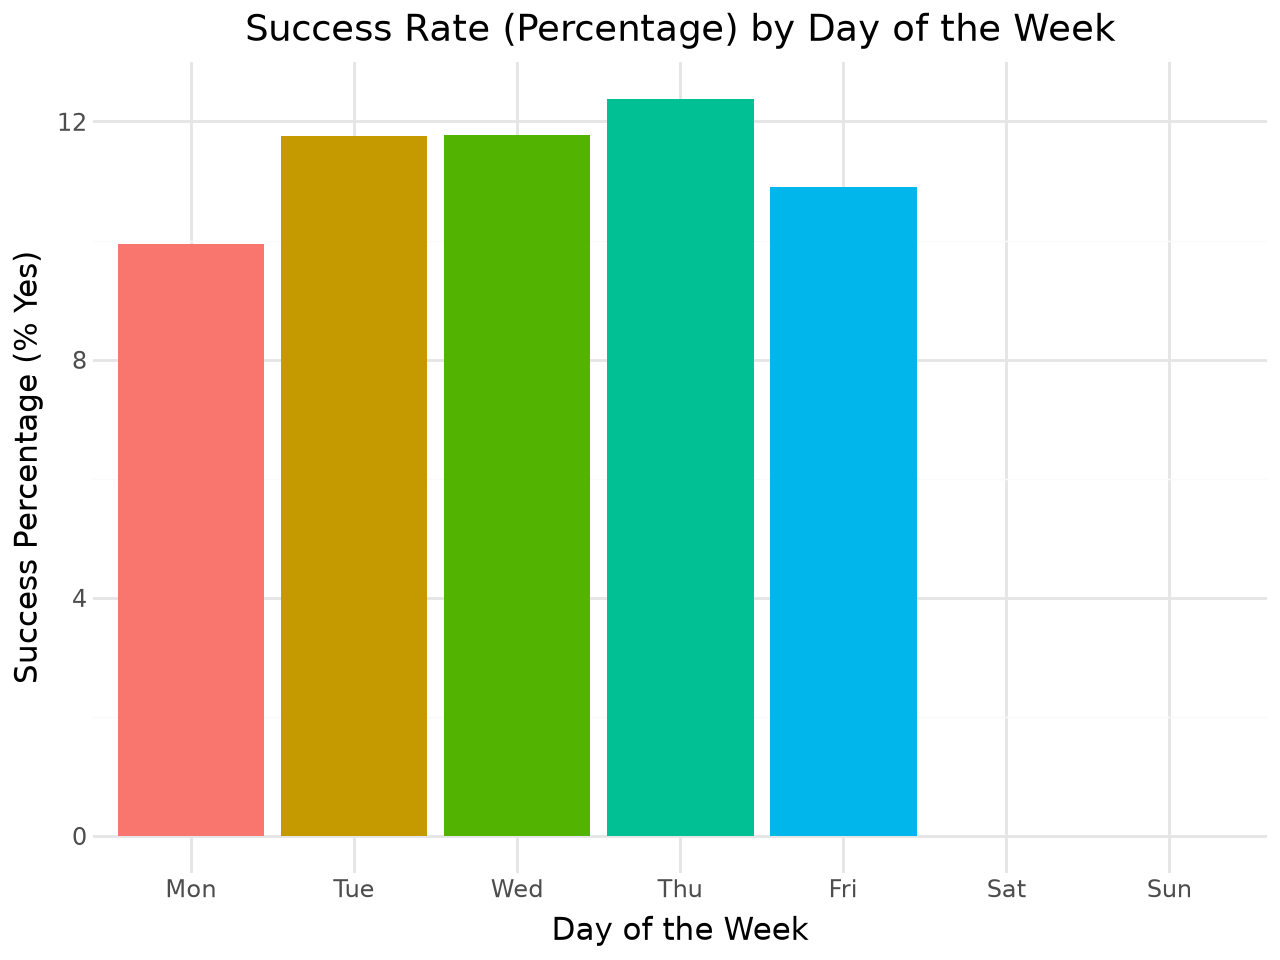

In [9]:
day_mapping = {
    'mon': 'Mon',
    'tue': 'Tue',
    'wed': 'Wed',
    'thu': 'Thu',
    'fri': 'Fri',
    'sat': 'Sat',
    'sun': 'Sun'
}

# Create a template DataFrame to ensure all days are represented
all_days = pl.DataFrame({"day_of_week": ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']})

# Calculate both total calls and successes per day to get percentages
day_stats = (
    clean
    .group_by("day_of_week")
    .agg([
        pl.len().alias("total_calls"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("success_count")
    ])
)

# Join, compute percentages, and clean up for plotting
success_percentages = (
    all_days
    .join(day_stats, on="day_of_week", how="left")
    .with_columns([
        pl.col("total_calls").fill_null(0),
        pl.col("success_count").fill_null(0)
    ])
    .with_columns(
        pl.when(pl.col("total_calls") > 0)
        .then((pl.col("success_count") / pl.col("total_calls")) * 100)
        .otherwise(0.0)
        .alias("success_percentage")
    )
    .with_columns(
        pl.col("day_of_week")
        .replace_strict(day_mapping)
        .cast(pl.Categorical())
        .alias("day_name")
    )
)

# Generate the plot representing percentage
graph = (
    ggplot(success_percentages, aes(x='day_name', y='success_percentage', fill='day_name'))
    + geom_col(show_legend=False)
    + theme_minimal()
    + labs(
        title="Success Rate (Percentage) by Day of the Week",
        x="Day of the Week",
        y="Success Percentage (% Yes)"
    )
)

graph

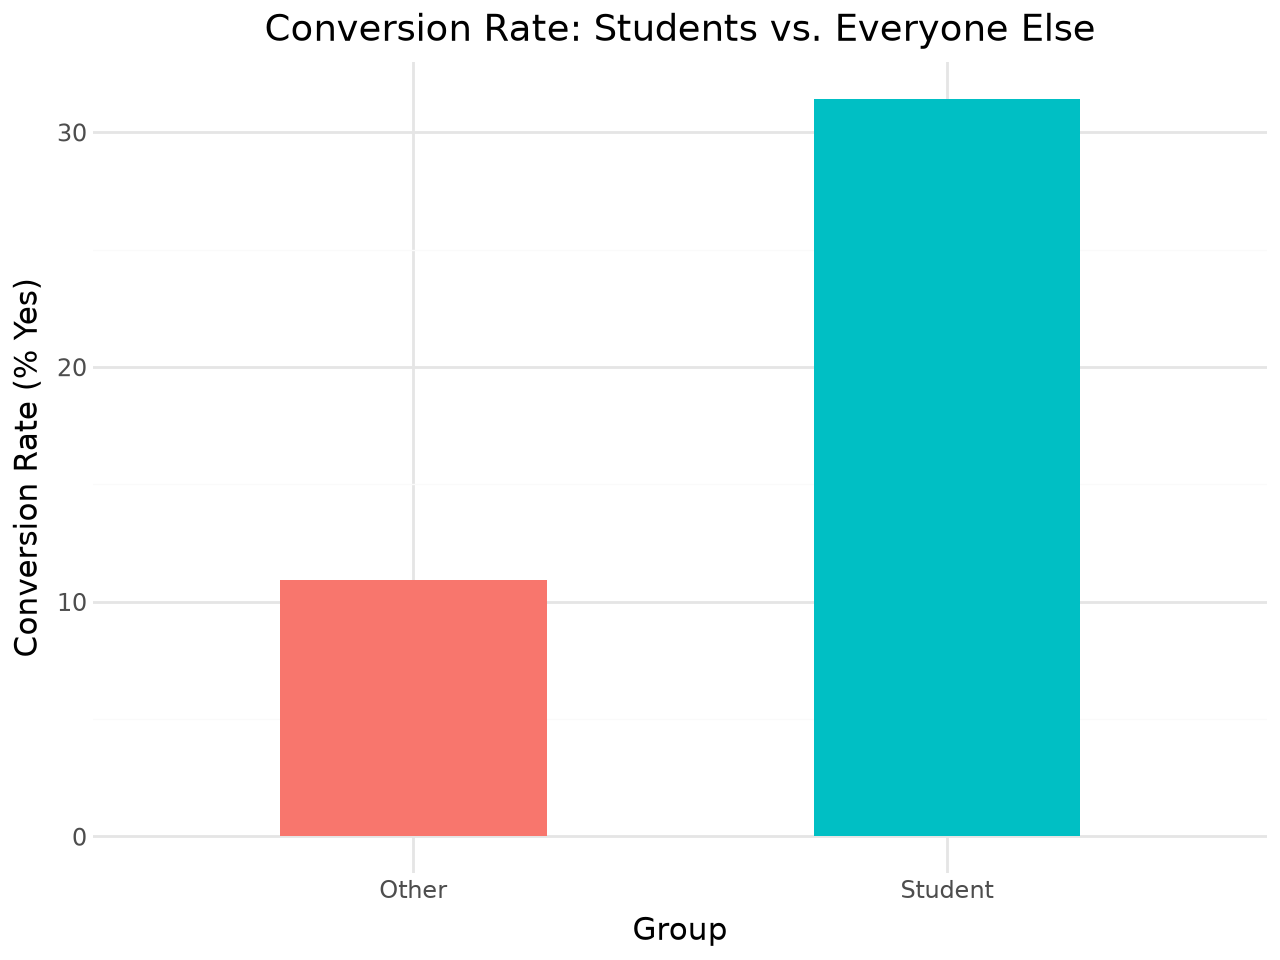

In [10]:
conversion_rates = (
    clean
    .with_columns(
        pl.when(pl.col("job") == "student")
        .then(pl.lit("Student"))
        .otherwise(pl.lit("Other"))
        .cast(pl.Categorical())
        .alias("group")
    )
    .group_by("group")
    .agg([
        pl.len().alias("total"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("yes_count")
    ])
    .with_columns(
        (pl.col("yes_count") / pl.col("total") * 100).alias("conversion_rate")
    )
)

(
    ggplot(conversion_rates, aes(x='group', y='conversion_rate', fill='group'))
    + geom_col(show_legend=False, width=0.5)
    + theme_minimal()
    + labs(
        title="Conversion Rate: Students vs. Everyone Else",
        x="Group",
        y="Conversion Rate (% Yes)"
    )
)

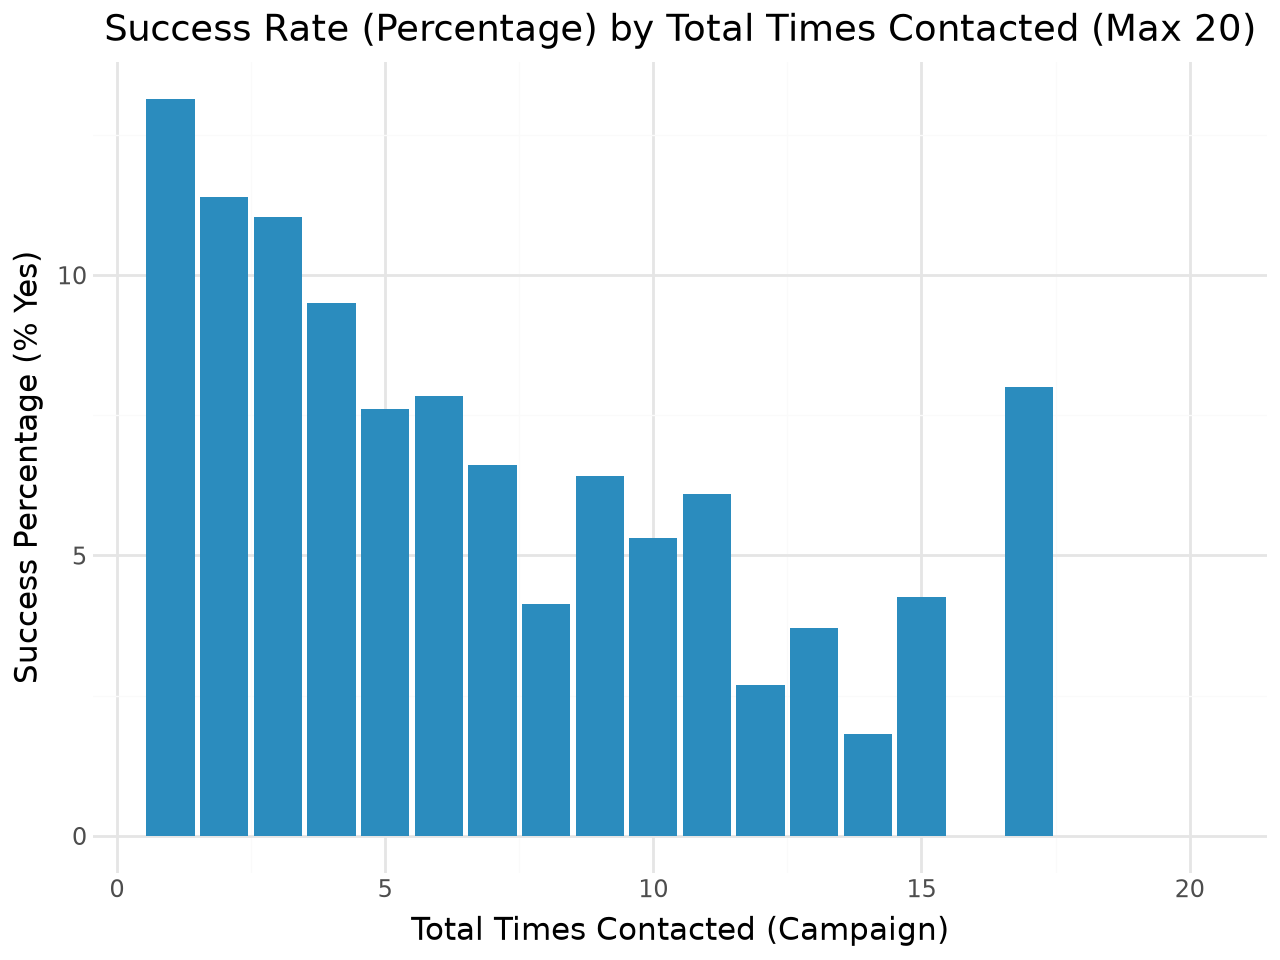

In [11]:
contact_stats = (
    clean
    .filter(pl.col("campaign") <= 20)
    .group_by("campaign")
    .agg([
        pl.len().alias("total_calls"),
        pl.col("y").filter(pl.col("y") == "yes").len().alias("success_count")
    ])
    .with_columns(
        ((pl.col("success_count") / pl.col("total_calls")) * 100).alias("success_percentage")
    )
    .sort("campaign")
)

(
    ggplot(contact_stats, aes(x='campaign', y='success_percentage'))
    + geom_col(fill='#2b8cbe')
    + theme_minimal()
    + labs(
        title="Success Rate (Percentage) by Total Times Contacted (Max 20)",
        x="Total Times Contacted (Campaign)",
        y="Success Percentage (% Yes)"
    )
)

## Choose calls by value

A prediction of 1 makes a call. Its value is **$44.64 if successful, minus
$5.50 regardless of outcome**. A prediction of 0 contributes $0.
The economic break-even threshold is about 0.1232 for calibrated probabilities.
Try thresholds on labeled validation customers only, then freeze the best one
before generating holdout predictions. Accuracy is shown above for context.

The table and curve are threshold-tuning results. The holdout has no labels,
so neither its actual Value of Calls nor its grade can be computed here.

In [12]:
CALL_COST = 5.50
SUCCESS_REVENUE = 44.64
BREAK_EVEN_THRESHOLD = CALL_COST / SUCCESS_REVENUE
# Include 0.5, the economic break-even point, call-everyone, and call-nobody.
THRESHOLDS = np.unique(np.r_[0.0, np.arange(0.01, 0.51, 0.01),
                             BREAK_EVEN_THRESHOLD, 1.01])

def value_of_calls(actual_y, predicted_y):
    actual = np.asarray(actual_y, dtype=int)
    predicted = np.asarray(predicted_y, dtype=int)
    assert actual.shape == predicted.shape
    assert set(np.unique(actual)) <= {0, 1}
    assert set(np.unique(predicted)) <= {0, 1}
    calls = int(predicted.sum())
    correct_calls = int(((actual == 1) & (predicted == 1)).sum())
    return {
        "calls": calls,
        "correct_calls": correct_calls,
        "call_cost": calls * CALL_COST,
        "revenue": correct_calls * SUCCESS_REVENUE,
        "value_of_calls": correct_calls * SUCCESS_REVENUE - calls * CALL_COST,
    }

def threshold_values(actual_y, probabilities):
    return pd.DataFrame([
        {"threshold": float(t),
         **value_of_calls(actual_y, (probabilities >= t).astype(int))}
        for t in THRESHOLDS
    ])

def best_threshold(table):
    # Break equal-value ties by making fewer calls, then the smaller threshold.
    return float(table.sort_values(
        ["value_of_calls", "calls", "threshold"],
        ascending=[False, True, True],
    ).iloc[0]["threshold"])

assert np.isclose(value_of_calls([1, 0, 1], [1, 1, 0])["value_of_calls"], 33.64)
assert value_of_calls([1, 0], [0, 0])["value_of_calls"] == 0
print(f"Break-even probability: {BREAK_EVEN_THRESHOLD:.4%}")


Break-even probability: 12.3208%


,threshold,calls,correct_calls,call_cost,revenue,value_of_calls
18,0.170000,1886,789,10373.0,35220.96,24847.96
17,0.160000,1977,799,10873.5,35667.36,24793.86
16,0.150000,2065,809,11357.5,36113.76,24756.26
19,0.180000,1833,779,10081.5,34774.56,24693.06
20,0.190000,1774,769,9757.0,34328.16,24571.16
15,0.140000,2188,819,12034.0,36560.16,24526.16
21,0.200000,1720,760,9460.0,33926.40,24466.40
14,0.130000,2321,832,12765.5,37140.48,24374.98
22,0.210000,1663,750,9146.5,33480.00,24333.50
13,0.123208,2412,842,13266.0,37586.88,24320.88


Selected threshold: 0.1700
Default {'calls': 558, 'correct_calls': 364, 'call_cost': 3069.0, 'revenue': 16248.960000000001, 'value_of_calls': 13179.960000000001}
Break-even {'calls': 2412, 'correct_calls': 842, 'call_cost': 13266.0, 'revenue': 37586.88, 'value_of_calls': 24320.879999999997}
Selected {'calls': 1886, 'correct_calls': 789, 'call_cost': 10373.0, 'revenue': 35220.96, 'value_of_calls': 24847.96}


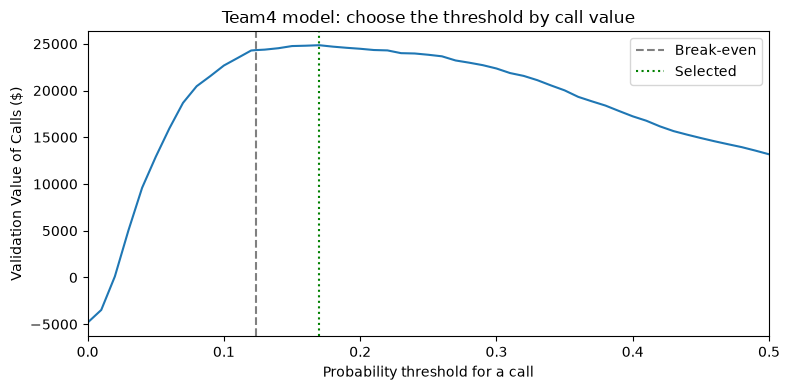

In [13]:
team_validation_probabilities = clf.predict_proba(X_test)[:, list(clf.classes_).index("yes")]
team_actual = (y_test == "yes").astype(int)
team_threshold_table = threshold_values(team_actual, team_validation_probabilities)
team_best_threshold = best_threshold(team_threshold_table)
team_threshold_table.to_csv(NOTEBOOK_DIR / "team4-value-thresholds.csv", index=False)
display(team_threshold_table.sort_values("value_of_calls", ascending=False).head(10))
print(f"Selected threshold: {team_best_threshold:.4f}")
for label, t in [("Default", 0.5), ("Break-even", BREAK_EVEN_THRESHOLD),
                 ("Selected", team_best_threshold)]:
    print(label, value_of_calls(team_actual, (team_validation_probabilities >= t).astype(int)))

pd.DataFrame({
    "source_row": X_test.index.to_numpy() + 1,
    "actual_y": team_actual,
    "probability_yes": team_validation_probabilities,
    "default_y": (team_validation_probabilities >= 0.5).astype(int),
    "value_y": (team_validation_probabilities >= team_best_threshold).astype(int),
}).sort_values("source_row").to_csv(NOTEBOOK_DIR / "team4-validation-predictions.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(team_threshold_table["threshold"], team_threshold_table["value_of_calls"])
plt.axvline(BREAK_EVEN_THRESHOLD, color="gray", linestyle="--", label="Break-even")
plt.axvline(team_best_threshold, color="green", linestyle=":", label="Selected")
plt.xlim(0, 0.5)
plt.xlabel("Probability threshold for a call")
plt.ylabel("Validation Value of Calls ($)")
plt.title("Team4 model: choose the threshold by call value")
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
# Refit only after validation; keep clf unchanged for honest row comparisons.
submission_model = clone(clf).fit(X, y)
team_holdout_probabilities = submission_model.predict_proba(holdout_X)[:,
    list(submission_model.classes_).index("yes")]
my_predictions = pl.DataFrame({"y": (team_holdout_probabilities >= 0.5).astype(np.int32)})
value_predictions = pl.DataFrame({"y": (team_holdout_probabilities >= team_best_threshold).astype(np.int32)})
for frame in [my_predictions, value_predictions]:
    assert frame.columns == ["y"]
    assert frame.height == test.height
    assert set(frame["y"].unique().to_list()) <= {0, 1}

my_predictions.write_csv(NOTEBOOK_DIR / "team4-module2-predictions.csv")
value_predictions.write_csv(NOTEBOOK_DIR / "team4-module2-value-predictions.csv")
pd.DataFrame({"source_row": np.arange(1, test.height + 1),
              "probability_yes": team_holdout_probabilities}).to_csv(
    NOTEBOOK_DIR / "team4-holdout-probabilities.csv", index=False)
print(f"Holdout rows: {test.height}")
print(f"Default calls: {my_predictions['y'].sum()}; value-tuned calls: {value_predictions['y'].sum()}")
print("Saved baseline and value-tuned submissions with one integer y column.")


Holdout rows: 4119
Default calls: 170; value-tuned calls: 645
Saved baseline and value-tuned submissions with one integer y column.
